# CSCI-4625 Final Project — Image Deblurring using Generative Adversarial Networks

### Team Members:
- ### Nakul Magotra
- ### Prasad Belsare

---

This notebook implements an end-to-end GAN-based image deblurring pipeline with **two generator backbones**:

- **Experiment 1:** DeblurGAN-v2–style generator with standard **ResNet residual blocks**  
- **Experiment 2:** DeblurGAN-v2–style generator with **Residual Dense Blocks (RDBs)**

Both experiments share the **same dataset, discriminator, and loss functions**, allowing a clean comparison of:

- Quantitative metrics (PSNR, SSIM)
- Qualitative results (side-by-side visualization)
- Design tradeoffs (training cost vs. detail preservation)


In [ ]:

# ======================================================================
# 0. Imports & Global Config
# ======================================================================

import os
import random
from glob import glob
from typing import Optional, List, Tuple, Dict

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import models, transforms

import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from torchvision.models import VGG19_Weights



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


class Config:
    # Data / training
    image_size: int = 256
    batch_size: int = 4
    num_workers: int = 0

    num_epochs_exp1: int = 5   # adjust for full training
    num_epochs_exp2: int = 5   # adjust for full training

    lr_g: float = 1e-4
    lr_d: float = 1e-4

    lambda_pixel: float = 100.0
    lambda_adv: float = 1.0
    lambda_percep: float = 10.0

    n_res_blocks: int = 8

    # Paths (update data_root to your local GoPro path)
    data_root: Optional[str] = None  # e.g. "./GOPRO_Large"
    save_dir: str = "./checkpoints_two_experiments"

    # Randomness
    seed: int = 42


cfg = Config()
os.makedirs(cfg.save_dir, exist_ok=True)


def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(cfg.seed)


Using device: cuda


In [ ]:

# ======================================================================
# 1. Metrics & Visualization Utilities
# ======================================================================

def tensor_to_img(t: torch.Tensor) -> np.ndarray:
    """Convert tensor in [-1,1] to HWC uint8."""
    t = t.detach().cpu().clamp(-1, 1)
    t = (t + 1.0) / 2.0  # [0,1]
    t = t.permute(1, 2, 0).numpy()
    t = (t * 255.0).round().astype(np.uint8)
    return t


def compute_psnr_tensor(pred: torch.Tensor, target: torch.Tensor) -> float:
    img1 = tensor_to_img(pred)
    img2 = tensor_to_img(target)
    return peak_signal_noise_ratio(img2, img1, data_range=255)


def compute_ssim_tensor(pred: torch.Tensor, target: torch.Tensor) -> float:
    img1 = tensor_to_img(pred)
    img2 = tensor_to_img(target)
    return structural_similarity(
        img2, img1, channel_axis=2, data_range=255
    )


def show_comparison(
    blur: torch.Tensor,
    sharp: torch.Tensor,
    out1: torch.Tensor,
    out2: torch.Tensor,
    title1: str = "ResNet Generator (Exp1)",
    title2: str = "RDB Generator (Exp2)",
) -> None:
    blur_img = tensor_to_img(blur)
    sharp_img = tensor_to_img(sharp)
    out1_img = tensor_to_img(out1)
    out2_img = tensor_to_img(out2)

    fig, ax = plt.subplots(1, 4, figsize=(16, 4))

    ax[0].imshow(blur_img)
    ax[0].set_title("Blurred Input")
    ax[0].axis("off")

    ax[1].imshow(sharp_img)
    ax[1].set_title("Ground Truth")
    ax[1].axis("off")

    ax[2].imshow(out1_img)
    ax[2].set_title(title1)
    ax[2].axis("off")

    ax[3].imshow(out2_img)
    ax[3].set_title(title2)
    ax[3].axis("off")

    plt.tight_layout()
    plt.show()


## 2. GoPro Deblurring Dataset Loader

The dataset class below expects paired **blurred** and **sharp** images arranged as:

```text
<data_root>/train/SEQ_ID/blur/*.png
<data_root>/train/SEQ_ID/sharp/*.png

<data_root>/test/SEQ_ID/blur/*.png
<data_root>/test/SEQ_ID/sharp/*.png
```


In [ ]:

# ======================================================================
# 2. GoPro Paired Dataset
# ======================================================================

class GoProDeblurDataset(Dataset):
    def __init__(
        self,
        root: str,
        split: str = "train",
        image_size: int = 256,
    ):
        super().__init__()
        assert split in {"train", "test", "val"}

        self.root = root
        self.split = split
        self.image_size = image_size

        seq_dirs = sorted(
            [
                d
                for d in glob(os.path.join(root, split, "*"))
                if os.path.isdir(d)
            ]
        )

        self.pairs: List[Tuple[str, str]] = []
        for seq in seq_dirs:
            blur_dir = os.path.join(seq, "blur")
            sharp_dir = os.path.join(seq, "sharp")
            if not os.path.isdir(blur_dir) or not os.path.isdir(sharp_dir):
                continue

            blur_imgs = sorted(glob(os.path.join(blur_dir, "*.*")))
            for b_path in blur_imgs:
                fname = os.path.basename(b_path)
                s_path = os.path.join(sharp_dir, fname)
                if os.path.exists(s_path):
                    self.pairs.append((b_path, s_path))

        self.transform = transforms.Compose(
            [
                transforms.Resize((image_size, image_size)),
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=[0.5, 0.5, 0.5],
                    std=[0.5, 0.5, 0.5],
                ),
            ]
        )

        print(
            f"[GoProDeblurDataset] split={split}, "
            f"found {len(self.pairs)} pairs."
        )

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        blur_path, sharp_path = self.pairs[idx]

        blur_img = Image.open(blur_path).convert("RGB")
        sharp_img = Image.open(sharp_path).convert("RGB")

        blur_t = self.transform(blur_img)
        sharp_t = self.transform(sharp_img)

        return {"blur": blur_t, "sharp": sharp_t}


In [ ]:
# ======================================================================
# 2.1 Download / locate GOPRO_Large dataset
# ======================================================================

from pathlib import Path
from urllib.request import urlretrieve
import zipfile

DOWNLOAD_URL = "https://huggingface.co/datasets/snah/GOPRO_Large/resolve/main/GOPRO_Large.zip"
WORK_DIR = Path.cwd()
ZIP_FILE = WORK_DIR / "GOPRO_Large.zip"

# The archive may extract train/ and test/ directly, or inside GOPRO_Large/.
def contains_gopro_splits(path):
    return (path / "train").is_dir() and (path / "test").is_dir()

candidate_roots = [WORK_DIR / "GOPRO_Large", WORK_DIR, Path("/content/GOPRO_Large"), Path("/content")]
data_root = next((p for p in candidate_roots if contains_gopro_splits(p)), None)

if data_root is None:
    print("Downloading GOPRO_Large (~9.5 GB ZIP); ensure enough disk space...")
    urlretrieve(DOWNLOAD_URL, ZIP_FILE)
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_FILE) as archive:
        archive.extractall(WORK_DIR)
    ZIP_FILE.unlink(missing_ok=True)
    data_root = next((p for p in candidate_roots if contains_gopro_splits(p)), None)

if data_root is None:
    raise FileNotFoundError("GoPro train/ and test/ directories not found after extraction.")

cfg.data_root = str(data_root)
print("Dataset root:", cfg.data_root)


In [ ]:

# ======================================================================
# 3. Create Train / Validation Dataloaders
# ======================================================================

import os

# Reuse the root detected in Section 2.1 (works with both possible archive layouts).
if cfg.data_root is None:
    raise ValueError("Run the dataset setup cell in Section 2.1 first.")

# Verify train and test folders exist
assert os.path.isdir(os.path.join(cfg.data_root, "train")), (
    f"Train directory not found: {cfg.data_root}/train"
)

assert os.path.isdir(os.path.join(cfg.data_root, "test")), (
    f"Test directory not found: {cfg.data_root}/test"
)

print(f"Dataset root: {cfg.data_root}")
print(f"Train folders: {os.listdir(os.path.join(cfg.data_root, 'train'))[:5]}")
print(f"Test folders: {os.listdir(os.path.join(cfg.data_root, 'test'))[:5]}")

# Create training dataset
train_dataset = GoProDeblurDataset(
    root=cfg.data_root,
    split="train",
    image_size=cfg.image_size,
)

# Use the test split for validation
val_dataset = GoProDeblurDataset(
    root=cfg.data_root,
    split="test",
    image_size=cfg.image_size,
)

# Verify datasets are not empty
if len(train_dataset) == 0:
    raise ValueError(f"Train dataset is empty. Check {cfg.data_root}/train structure.")

if len(val_dataset) == 0:
    raise ValueError(f"Validation dataset is empty. Check {cfg.data_root}/test structure.")

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")

# Create training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=cfg.batch_size,
    shuffle=True,
    num_workers=cfg.num_workers,
    pin_memory=True,
)

# Create validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=cfg.num_workers,
    pin_memory=True,
)

print("Train and validation DataLoaders created successfully!")


## 4. Model Definitions

We define:

- A **ResNet-style generator** (Experiment 1)
- An **RDB-style generator** (Experiment 2)
- A shared **Patch Discriminator** for GAN training


In [ ]:

# ======================================================================
# 4.1 Residual Block for Experiment 1
# ======================================================================

class ResidualBlock(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(dim, dim, 3, 1, 1, bias=False),
            nn.InstanceNorm2d(dim, affine=True),
            nn.ReLU(inplace=True),
            nn.Conv2d(dim, dim, 3, 1, 1, bias=False),
            nn.InstanceNorm2d(dim, affine=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.block(x)


class DeblurGeneratorResNet(nn.Module):
    def __init__(
        self,
        in_channels: int = 3,
        out_channels: int = 3,
        n_res_blocks: int = 8,
        base_channels: int = 64,
    ):
        super().__init__()

        # Encoder
        model = [
            nn.Conv2d(in_channels, base_channels, 7, 1, 3, bias=False),
            nn.InstanceNorm2d(base_channels, affine=True),
            nn.ReLU(inplace=True),
        ]
        model += [
            nn.Conv2d(base_channels, base_channels * 2, 3, 2, 1, bias=False),
            nn.InstanceNorm2d(base_channels * 2, affine=True),
            nn.ReLU(inplace=True),
        ]
        model += [
            nn.Conv2d(
                base_channels * 2, base_channels * 4, 3, 2, 1, bias=False
            ),
            nn.InstanceNorm2d(base_channels * 4, affine=True),
            nn.ReLU(inplace=True),
        ]

        # Residual blocks
        for _ in range(n_res_blocks):
            model.append(ResidualBlock(base_channels * 4))

        # Decoder
        model += [
            nn.ConvTranspose2d(
                base_channels * 4,
                base_channels * 2,
                4,
                2,
                1,
                bias=False,
            ),
            nn.InstanceNorm2d(base_channels * 2, affine=True),
            nn.ReLU(inplace=True),
        ]
        model += [
            nn.ConvTranspose2d(
                base_channels * 2, base_channels, 4, 2, 1, bias=False
            ),
            nn.InstanceNorm2d(base_channels, affine=True),
            nn.ReLU(inplace=True),
        ]
        model += [
            nn.Conv2d(base_channels, out_channels, 7, 1, 3),
            nn.Tanh(),
        ]

        self.net = nn.Sequential(*model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


In [ ]:

# ======================================================================
# 4.2 Residual Dense Block & RDB Generator for Experiment 2
# ======================================================================

class ResidualDenseBlock(nn.Module):
    def __init__(self, channels: int, growth: int = 32):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, growth, 3, 1, 1)
        self.conv2 = nn.Conv2d(channels + growth, growth, 3, 1, 1)
        self.conv3 = nn.Conv2d(channels + 2 * growth, growth, 3, 1, 1)
        self.conv4 = nn.Conv2d(channels + 3 * growth, growth, 3, 1, 1)
        self.lff = nn.Conv2d(channels + 4 * growth, channels, 1, 1, 0)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        c1 = self.relu(self.conv1(x))
        c2 = self.relu(self.conv2(torch.cat([x, c1], dim=1)))
        c3 = self.relu(self.conv3(torch.cat([x, c1, c2], dim=1)))
        c4 = self.relu(self.conv4(torch.cat([x, c1, c2, c3], dim=1)))
        fused = self.lff(torch.cat([x, c1, c2, c3, c4], dim=1))
        return fused + x


class DeblurGeneratorRDB(nn.Module):
    def __init__(
        self,
        in_channels: int = 3,
        out_channels: int = 3,
        n_rdb_blocks: int = 8,
        base_channels: int = 64,
        growth: int = 32,
    ):
        super().__init__()

        # Encoder
        model = [
            nn.Conv2d(in_channels, base_channels, 7, 1, 3, bias=False),
            nn.InstanceNorm2d(base_channels, affine=True),
            nn.ReLU(inplace=True),
        ]
        model += [
            nn.Conv2d(base_channels, base_channels * 2, 3, 2, 1, bias=False),
            nn.InstanceNorm2d(base_channels * 2, affine=True),
            nn.ReLU(inplace=True),
        ]
        model += [
            nn.Conv2d(
                base_channels * 2, base_channels * 4, 3, 2, 1, bias=False
            ),
            nn.InstanceNorm2d(base_channels * 4, affine=True),
            nn.ReLU(inplace=True),
        ]

        # RDB blocks
        for _ in range(n_rdb_blocks):
            model.append(
                ResidualDenseBlock(base_channels * 4, growth=growth)
            )

        # Decoder
        model += [
            nn.ConvTranspose2d(
                base_channels * 4,
                base_channels * 2,
                4,
                2,
                1,
                bias=False,
            ),
            nn.InstanceNorm2d(base_channels * 2, affine=True),
            nn.ReLU(inplace=True),
        ]
        model += [
            nn.ConvTranspose2d(
                base_channels * 2, base_channels, 4, 2, 1, bias=False
            ),
            nn.InstanceNorm2d(base_channels, affine=True),
            nn.ReLU(inplace=True),
        ]
        model += [
            nn.Conv2d(base_channels, out_channels, 7, 1, 3),
            nn.Tanh(),
        ]

        self.net = nn.Sequential(*model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


# ======================================================================
# 4.3 Patch Discriminator
# ======================================================================

class PatchDiscriminator(nn.Module):
    def __init__(self, in_channels: int = 3):
        super().__init__()

        def conv_layer(in_c, out_c, stride):
            layers = [
                nn.Conv2d(in_c, out_c, 4, stride, 1, bias=False),
                nn.InstanceNorm2d(out_c, affine=True),
                nn.LeakyReLU(0.2, inplace=True),
            ]
            return layers

        layers = [
            nn.Conv2d(in_channels, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),
        ]
        layers += conv_layer(64, 128, 2)
        layers += conv_layer(128, 256, 2)
        layers += conv_layer(256, 512, 1)
        layers += [nn.Conv2d(512, 1, 4, 1, 1)]

        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


## 5. VGG Perceptual Loss

We use a pre-trained VGG-19 network to compute a perceptual loss in feature space, as in DeblurGAN-v2.


In [ ]:

# ======================================================================
# 5. Perceptual Loss (VGG19)
# ======================================================================

class VGGPerceptualLoss(nn.Module):
    def __init__(self, resize: bool = True):
        super().__init__()

        # Try to load pretrained weights; if SSL or download fails, fall back.
        try:
            print("Loading VGG19 with ImageNet pretrained weights...")
            vgg = models.vgg19(weights=VGG19_Weights.IMAGENET1K_V1)
        except Exception as e:
            print(
                "WARNING: Could not load pretrained VGG19 weights "
                f"({type(e).__name__}: {e}).\n"
                "Falling back to randomly initialized VGG19. "
                "Perceptual loss will be weaker, but training can continue."
            )
            vgg = models.vgg19(weights=None)

        self.features = vgg.features[:16].eval()
        for param in self.features.parameters():
            param.requires_grad = False

        self.register_buffer(
            "mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1),
        )
        self.register_buffer(
            "std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1),
        )
        self.resize = resize

    def forward(self, x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        # x, y in [-1,1]; convert back to [0,1] then normalize with ImageNet stats
        def norm_im(t):
            t = (t + 1.0) / 2.0
            return (t - self.mean) / self.std

        x = norm_im(x)
        y = norm_im(y)

        feats_x = self.features(x)
        feats_y = self.features(y)
        return torch.mean(torch.abs(feats_x - feats_y))



## 6. GAN Training Utilities

We use a standard **LSGAN-style adversarial loss**:

- Discriminator tries to predict `1` for real sharp images and `0` for generated images
- Generator tries to fool the discriminator and is additionally guided by:
  - Pixel L1 loss
  - VGG-based perceptual loss


In [ ]:

# ======================================================================
# 6. Adversarial Loss Helpers
# ======================================================================

adv_criterion = nn.MSELoss()
pixel_criterion = nn.L1Loss()
perceptual_criterion = VGGPerceptualLoss().to(device)


def d_loss_fn(
    discriminator: PatchDiscriminator,
    real: torch.Tensor,
    fake: torch.Tensor,
) -> torch.Tensor:
    pred_real = discriminator(real)
    pred_fake = discriminator(fake.detach())

    valid = torch.ones_like(pred_real)
    fake_label = torch.zeros_like(pred_fake)

    loss_real = adv_criterion(pred_real, valid)
    loss_fake = adv_criterion(pred_fake, fake_label)
    return 0.5 * (loss_real + loss_fake)


def g_loss_fn(
    discriminator: PatchDiscriminator,
    fake: torch.Tensor,
    real: torch.Tensor,
) -> Tuple[torch.Tensor, Dict[str, float]]:
    pred_fake = discriminator(fake)
    valid = torch.ones_like(pred_fake)

    adv_loss = adv_criterion(pred_fake, valid)
    pix_loss = pixel_criterion(fake, real)
    perc_loss = perceptual_criterion(fake, real)

    g_loss = (
        cfg.lambda_adv * adv_loss
        + cfg.lambda_pixel * pix_loss
        + cfg.lambda_percep * perc_loss
    )

    logs = {
        "adv": adv_loss.item(),
        "pixel": pix_loss.item(),
        "percep": perc_loss.item(),
        "total": g_loss.item(),
    }
    return g_loss, logs


Loading VGG19 with ImageNet pretrained weights...
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:02<00:00, 242MB/s]


## 7. Training Loop per Experiment

We define a reusable training function that accepts a **generator constructor** and an experiment name.

We call it twice:

- Once with `DeblurGeneratorResNet`  → **Experiment 1**
- Once with `DeblurGeneratorRDB`     → **Experiment 2**


In [ ]:

# ======================================================================
# 7. Train a Single Experiment
# ======================================================================

def train_experiment(
    exp_name: str,
    gen_ctor,
    num_epochs: int,
) -> Tuple[nn.Module, Dict[str, List[float]]]:
    generator = gen_ctor().to(device)
    discriminator = PatchDiscriminator().to(device)

    opt_g = optim.Adam(generator.parameters(), lr=cfg.lr_g, betas=(0.5, 0.999))
    opt_d = optim.Adam(discriminator.parameters(), lr=cfg.lr_d, betas=(0.5, 0.999))

    history = {
        "g_total": [],
        "d_loss": [],
    }

    for epoch in range(num_epochs):
        generator.train()
        discriminator.train()

        pbar = tqdm(train_loader, desc=f"{exp_name} | Epoch {epoch+1}/{num_epochs}")
        for batch in pbar:
            blur = batch["blur"].to(device, non_blocking=True)
            sharp = batch["sharp"].to(device, non_blocking=True)

            # ---------------------
            #  Train Discriminator
            # ---------------------
            opt_d.zero_grad(set_to_none=True)
            fake = generator(blur)
            loss_d = d_loss_fn(discriminator, sharp, fake)
            loss_d.backward()
            opt_d.step()

            # ---------------------
            #  Train Generator
            # ---------------------
            opt_g.zero_grad(set_to_none=True)
            fake = generator(blur)
            loss_g, logs_g = g_loss_fn(discriminator, fake, sharp)
            loss_g.backward()
            opt_g.step()

            history["g_total"].append(logs_g["total"])
            history["d_loss"].append(loss_d.item())

            pbar.set_postfix(
                g_total=logs_g["total"],
                d_loss=loss_d.item(),
            )

        # Save checkpoint after each epoch
        ckpt_path = os.path.join(
            cfg.save_dir, f"{exp_name}_generator_epoch{epoch+1}.pth"
        )
        torch.save(generator.state_dict(), ckpt_path)

    return generator, history


## 8. Run Experiment 1 (ResNet) and Experiment 2 (RDB)

This section trains both generators sequentially.


In [ ]:

# ======================================================================
# 8. Launch Training for Both Experiments
# ======================================================================

# Experiment 1: ResNet-based generator
gen_resnet, hist_resnet = train_experiment(
    exp_name="exp1_resnet",
    gen_ctor=lambda: DeblurGeneratorResNet(
        in_channels=3,
        out_channels=3,
        n_res_blocks=cfg.n_res_blocks,
        base_channels=64,
    ),
    num_epochs=cfg.num_epochs_exp1,
)

# Experiment 2: RDB-based generator
gen_rdb, hist_rdb = train_experiment(
    exp_name="exp2_rdb",
    gen_ctor=lambda: DeblurGeneratorRDB(
        in_channels=3,
        out_channels=3,
        n_rdb_blocks=cfg.n_res_blocks,
        base_channels=64,
        growth=32,
    ),
    num_epochs=cfg.num_epochs_exp2,
)


exp1_resnet | Epoch 1/5:   0%|          | 0/526 [00:00<?, ?it/s]

exp1_resnet | Epoch 2/5:   0%|          | 0/526 [00:00<?, ?it/s]

exp1_resnet | Epoch 3/5:   0%|          | 0/526 [00:00<?, ?it/s]

exp1_resnet | Epoch 4/5:   0%|          | 0/526 [00:00<?, ?it/s]

exp1_resnet | Epoch 5/5:   0%|          | 0/526 [00:00<?, ?it/s]

exp2_rdb | Epoch 1/5:   0%|          | 0/526 [00:00<?, ?it/s]

exp2_rdb | Epoch 2/5:   0%|          | 0/526 [00:00<?, ?it/s]

exp2_rdb | Epoch 3/5:   0%|          | 0/526 [00:00<?, ?it/s]

exp2_rdb | Epoch 4/5:   0%|          | 0/526 [00:00<?, ?it/s]

exp2_rdb | Epoch 5/5:   0%|          | 0/526 [00:00<?, ?it/s]

## 9. Evaluation: PSNR & SSIM on Validation Set

We now evaluate both trained generators on the same validation split and compute:

- Average PSNR
- Average SSIM


In [ ]:

# ======================================================================
# 9. Evaluate Both Experiments
# ======================================================================

def evaluate_generator(
    generator: nn.Module,
    data_loader: DataLoader,
    max_batches: Optional[int] = None,
) -> Tuple[float, float]:
    generator.eval()
    psnrs, ssims = [], []

    with torch.no_grad():
        for i, batch in enumerate(data_loader):
            blur = batch["blur"].to(device, non_blocking=True)
            sharp = batch["sharp"].to(device, non_blocking=True)

            fake = generator(blur)

            for b in range(blur.size(0)):
                p = compute_psnr_tensor(fake[b], sharp[b])
                s = compute_ssim_tensor(fake[b], sharp[b])
                psnrs.append(p)
                ssims.append(s)

            if max_batches is not None and (i + 1) >= max_batches:
                break

    mean_psnr = float(np.mean(psnrs)) if psnrs else 0.0
    mean_ssim = float(np.mean(ssims)) if ssims else 0.0
    return mean_psnr, mean_ssim


psnr_resnet, ssim_resnet = evaluate_generator(gen_resnet, val_loader)
psnr_rdb, ssim_rdb = evaluate_generator(gen_rdb, val_loader)

print("Experiment 1 (ResNet)  - PSNR: {:.3f}, SSIM: {:.4f}".format(psnr_resnet, ssim_resnet))
print("Experiment 2 (RDB)     - PSNR: {:.3f}, SSIM: {:.4f}".format(psnr_rdb, ssim_rdb))


Experiment 1 (ResNet)  - PSNR: 23.555, SSIM: 0.8327
Experiment 2 (RDB)     - PSNR: 24.675, SSIM: 0.8484


## 10. Side-by-Side Qualitative Comparison

We pick a few samples from the validation set and show:

- Blurred input
- Ground-truth sharp image
- Experiment 1 (ResNet generator) output
- Experiment 2 (RDB generator) output


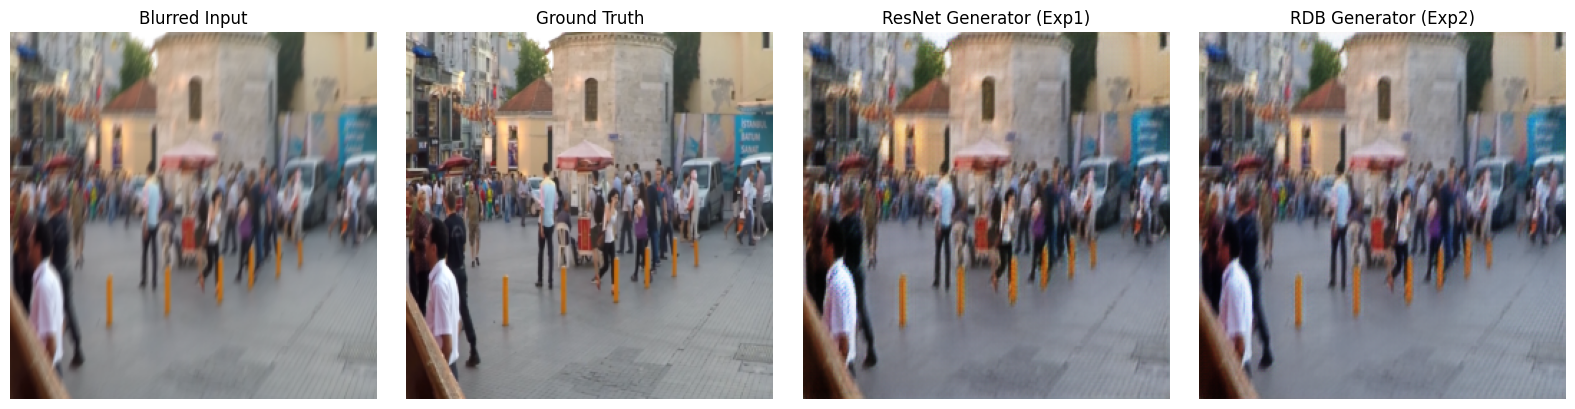

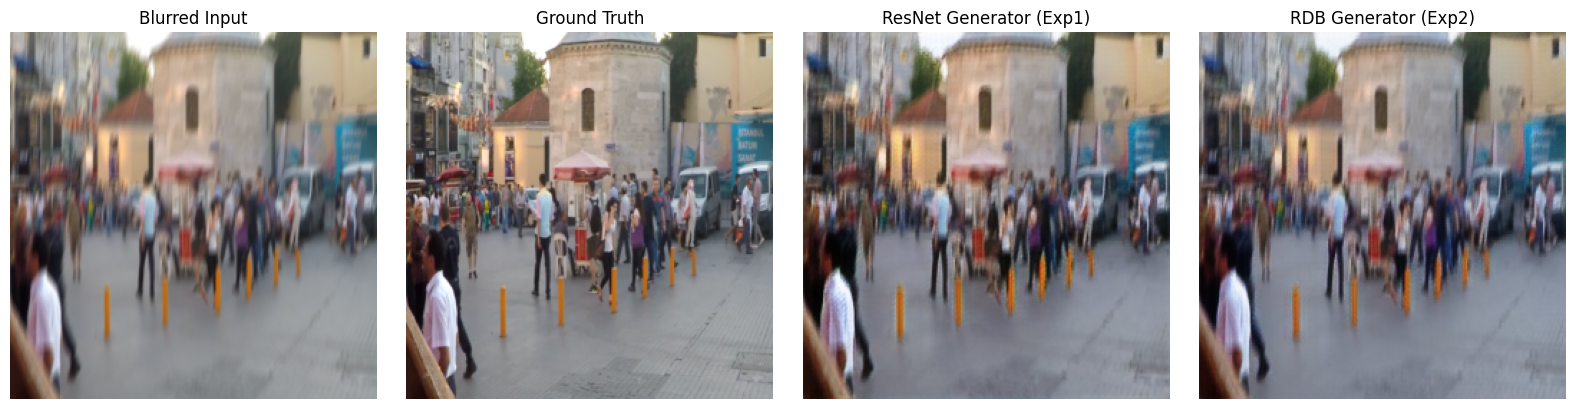

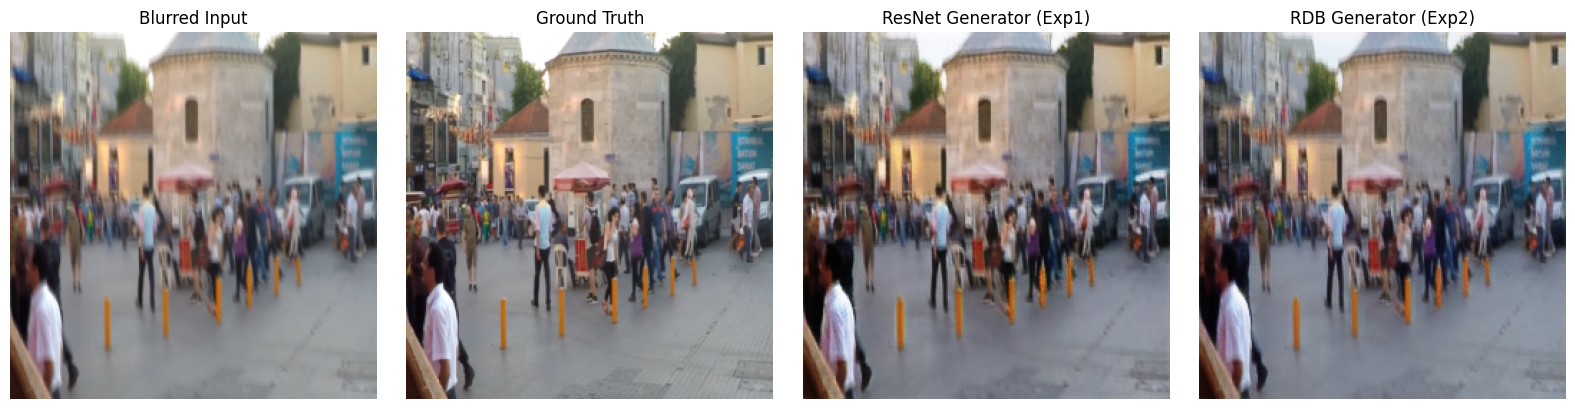

In [ ]:

# ======================================================================
# 10. Visualize Side-by-Side Results
# ======================================================================

gen_resnet.eval()
gen_rdb.eval()

with torch.no_grad():
    for i, batch in enumerate(val_loader):
        blur = batch["blur"].to(device, non_blocking=True)
        sharp = batch["sharp"].to(device, non_blocking=True)

        out1 = gen_resnet(blur)
        out2 = gen_rdb(blur)

        # Only visualize the first image in the batch
        show_comparison(
            blur[0],
            sharp[0],
            out1[0],
            out2[0],
            title1="ResNet Generator (Exp1)",
            title2="RDB Generator (Exp2)",
        )

        if i >= 2:
            break


## 11. Save Final Generators

We save the final trained weights for both experiments.


In [ ]:

# ======================================================================
# 11. Save Final Weights
# ======================================================================

torch.save(
    gen_resnet.state_dict(),
    os.path.join(cfg.save_dir, "generator_exp1_resnet_final.pth"),
)
torch.save(
    gen_rdb.state_dict(),
    os.path.join(cfg.save_dir, "generator_exp2_rdb_final.pth"),
)

print("Saved final generator weights to:", cfg.save_dir)


Saved final generator weights to: ./checkpoints_two_experiments
